In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from functools import partial
from scipy.integrate import quad
import warnings
warnings.filterwarnings('ignore')

#plotting parametere
newparams = {'figure.figsize': (8.0, 4.0), 'axes.grid': True,
'lines.markersize': 8, 'lines.linewidth': 2,
'font.size': 8}
plt.rcParams.update(newparams)


## Excircice 1 

#### 1a)

Vi finner den tidsderiverte (venstre side)

$$
\frac{\partial \phi}{\partial t} = \frac{\partial}{\partial t} \left[ \frac{1}{\sqrt{4\pi D t}} \int_{-\infty}^{\infty} dy \, h(y) e^{-\frac{(x-y)^2}{4Dt}} \right]
$$

og får 

$$
\frac{\partial \phi}{\partial t} = \int_{-\infty}^{\infty} dy \, h(y) \left( -\frac{1}{2t} + \frac{(x-y)^2}{4Dt^2} \right) \frac{1}{\sqrt{4\pi D t}} e^{-\frac{(x-y)^2}{4Dt}}.
$$

Vi regner første romderiverte (høyre side)

$$
\frac{\partial}{\partial x} \left[ \frac{1}{\sqrt{4\pi D t}} \int_{-\infty}^{\infty} dy \, h(y) e^{-\frac{(x-y)^2}{4Dt}} \right] =
 -\frac{1}{2Dt} \frac{1}{\sqrt{4\pi Dt}} \int_{-\infty}^{\infty} dy \, h(y) (x - y) e^{-\frac{(x - y)^2}{4Dt}}.
$$

Vi regner andre romderiverte (høyre side)

$$
D \frac{\partial^2 \phi}{\partial x^2} = \frac{1}{\sqrt{4\pi Dt}} \int_{-\infty}^{\infty} dy \, h(y) e^{-\frac{(x - y)^2}{4Dt}} \left(- \frac{1}{2t} + \frac{(x - y)^2}{4D t^2} \right).
$$

multipliserer begge sider med D gjenkjenner vi resten av utrykket som det samme utrykket som for tidsderiverte

$$
D \frac{\partial^2 \phi}{\partial x^2} = \frac{\partial \phi}{\partial t}.
$$

Med dette, oppfyller $ \phi(x,t) $ varmelikningen

Med $\sigma = \sqrt{2Dt}$, får vi
$$
\phi(x, \sigma) =  \int_{-\infty}^{\infty} dy\, h(y) \frac{1}{\sqrt{2 \pi }\sqrt{\sigma}} e^{-\frac{1}{2}\frac{(x-y)^2}{\sigma ^2}},
$$

Dette er et integral av en gaussisk funksjon, skalert av funksjonen $h(y)$. 

Den gaussiske funksjonen beskriver hvordan bidrag fra et startpunkt y fordeler seg i rommet over tid ved diffusjon. For hvert startpunkt y, beksriver den Gausisske faktoren sannsynsligheten for at den partikkelen som startet i y, befinner seg i x etter tiden t. Løsningen $ \phi(x,t) $ fås ved å summere bidragene fra alle startpunkter, vektet med den opprinnelige fordelingen $ h(y) $

Når $ t \to 0 $, går $\sigma \to 0$, blir den Gaussiske funksjonen ekstremt smal rundt y=x, samtidig som arealet under kruven forblir lik 1. I denne grensen oppfører den Gaussiske funksjonen seg som en dirac-delta funksjon med parameter $y-x$.

$$
\lim_{t \to 0} \phi(x,t) = \int_{-\infty}^{\infty} dy \, h(y) \delta(y - x),
$$

Som kan forenkles til

$$
\phi(x,0) = h(x).
$$

Dette betyr at $ h(y) $ representerer den initielle fordelingen av partikler langs x-aksen ved t=0. 

##### 1b)


Vi har relasjonene:
$$
p^+ \propto P(x_0 + 1), \quad p^- \propto P(x_0 - 1), \quad p^0 \propto P(x_0),
$$
Sammen med definisjonen av sannsynlighet gir:
$$
p^+ = \frac{P(x_0 + 1)}{P(x_0) + P(x_0 + 1) + P(x_0 - 1)},
$$
samme vil være sant for $ p^- $ og $ p^0 $. Ved å substutiere inn $ P(x) = e^{-\beta V(x)} / Z $, gir oss
$$
p^+ = \frac{e^{-\beta V(x_0 + 1)}}{e^{-\beta V(x_0)} + e^{-\beta V(x_0 + 1)} + e^{-\beta V(x_0 - 1)}}
$$
Som videre forenkles til
$$
p^+ = \frac{1}{1 + e^{-\beta [V(x_0 - 1) - V(x_0 + 1)]} + e^{-\beta [V(x_0) - V(x_0 + 1)]}}
$$

Samme for $ p^- $ og $ p^0 $, gir oss
$$
p^- = \frac{1}{1 + e^{-\beta [V(x_0 + 1) - V(x_0 - 1)]} + e^{-\beta [V(x_0) - V(x_0 - 1)]}}
$$
og
$$
p^0 = \frac{1}{1 + e^{-\beta [V(x_0 + 1) - V(x_0)]} + e^{-\beta [V(x_0 - 1) - V(x_0)]}}
$$

#### 1c)

I høytemperaturgrensen $k_B T \gg |V(x+1) - V(x)|$ , vil de eksponensielle leddene nærme seg 1. Dermed blir overgangssansynlighetene $p^+$, $p^0$, og $p^-$ all tilnærmet like og nær $1/3$. Når temperaturen er høy, har partiklene mye termisk energi. Denne energien er mye større enn forskjellen i potensialet mellom nabopunktene. Det betyr at partiklene nesten ikke "merker" potensialet. Som følge av dette blir sannsynlighetene for å gå fremover, bakover eller bli stående omtrent like store. Partiklene beveger seg derfor tilfelif  uten noen foretrukken retning. Bevegelsen kan da beskrives som en symmetrisk og isotrop tilfeldig vandring. 


I lavtemperaturgrensen $k_B T \ll |V(x+1) - V(x)|$, blir $\beta$ stor, slik at selv små forskjeller i potensialet får stor betydning. Dette fører til at enten $p^+$ or $p^-$ går mot 1, mens de øvringe overgangssannsynlighetene går mot 0. Når temperaturen er lav, har partiklene lite termisk energi. Da får selv små forskjeller i potensialet stor betydning for hvordan partiklene beveger seg. I dette tilfellet vil partiklene nesten alltid bevege seg i retning av lavere potensial. Overgangssanssynligheten i denne retningen blir nær 1, mens de andre blir nærmere 0. Bevegelsen blir derfor ikke lenger tilfelidg, men styrt av potensialet. 


I høytemperaturtilfellet kan potensialet derfor neglisjerer sammenlignet med de termiske fluktuasjonene, og systemet kan modelleres som en symmetrisk tilfeldig vandring. I lavtemperaturtilfellet vil partiklene derimot systematisk bevege seg mot lavere potensial, noe som innebærer at partiklene etter hvert vil konsentrere seg i områdene nær potensialminimum. 

## Excercice 2

##### 2a)


In [ ]:

Np = 101 #antall partikler, må være oddetall for dte skal være en partikkel i midten
Tp = 200 #antall iterasjoner
runs = 100 #antall ganger vi kjører simWalk
h = 1 #skrittlengde
dt = 1 #tidssteg
k = 1.0 #styrken på potensialet
B = 1.0 #invers temperatur


np.random.seed(7)

def V_const(x, k):
    return k * np.ones_like(x, dtype=float) #for V(x)=k, lager et array med bare k

def V_linear(x, k): #for V(x)=-k*x
    return -k * x

def pPlus(Vfunc, B, pos, k):
    return 1.0 / (1.0+ np.exp(-B*(Vfunc(pos-1, k) - Vfunc(pos+1, k)))+ np.exp(-B*(Vfunc(pos,   k) - Vfunc(pos+1, k))))

def pMin(Vfunc, B, pos, k):
    return 1.0 / (1.0+ np.exp(-B*(Vfunc(pos+1, k) - Vfunc(pos-1, k)))+ np.exp(-B*(Vfunc(pos,   k) - Vfunc(pos-1, k))))

def simStep(Vfunc, B, pos, h, k):
    p_plus = pPlus(Vfunc, B, pos, k) #pPlus gir sannsynligheten for å gå til høyre, og pMin gor å gå til venstre
    p_min  = pMin(Vfunc, B, pos, k)

    r = np.random.uniform(size=pos.size) #genererer et array med tilfeldige tall mellom 0 og 1, som skal brukes til å bestemme om vi går til høyre eller venstre

    pos = pos.copy() #lager en kopi av pos, slik at vi ikke endrer på originalen mens vi irerer gjennom den. Pos er et array som representerer posisjonen til hver partikkel, og vi skal oppdatere denne basert på sannsynligheten for at hver partikkkel er der.
    pos[r <= p_min] -= h #hvis det tilfeldige taller er mindre eller lik p_min, så går vi til venstre, og pos oppdatered ved å trekke h fra den. 
    pos[r > 1 - p_plus] += h
    return pos

def simWalk(Vfunc, B, pos0, Tp, dt, h, k): #simulerer en random walk for alle partikler i pos0, og retirnerer den endelige posisjonen etter Tp iterasjoner
    pos = pos0.copy()
    for _ in range(int(Tp/dt)): 
        pos = simStep(Vfunc, B, pos, h, k) 
    return pos

def run_case(Vfunc, B, V_label, pos0_mode="spread", a=False, xlim=None): #kjører simWalk flere ganger, og plotter histogram av den endelige posisjonen til alle partikler etter Tp iterasjoner. 
    if pos0_mode == "spread":
        pos0 = np.arange(Np) - Np//2
    else:
        pos0 = np.zeros(Np, dtype=int)

    all_final = [] #lager en tom liste som skal fylles med den endelige posisjonen til alle partikler etter Tp iterasjoner.
    for _ in range(runs):
        all_final.append(simWalk(Vfunc, B, pos0, Tp, dt, h, k))
    all_final = np.concatenate(all_final)

    print("pos0 min/max:", pos0.min(), pos0.max())
    print("final min/max:", all_final.min(), all_final.max(), "mean:", all_final.mean())

    if a==True: #hvis jeg skal ha normalfordeling på hsitogrammet
        mu = np.mean(all_final) #beregner gjennomsnittet av den 
        sigma = np.std(all_final)

        x = np.linspace(all_final.min(), all_final.max(), 400)
        pdf = (1/(sigma*np.sqrt(2*np.pi))) * np.exp(-0.5*((x-mu)/sigma)**2)





    plt.figure()
    plt.hist(all_final, bins=150, density=True, alpha=0.6,
             color="deeppink", label=rf'$\beta k={B*k:.2f}$')
    if a==True:
        plt.plot(x, pdf, color="blue", linewidth=3, label=rf'Fitted normal ($\mu={mu:.2f}, \sigma={sigma:.2f}$)')
    plt.title(rf"Random walk når {V_label}")
    plt.xlabel(rf"Position after {Tp} iterations, $x$")
    plt.ylabel("Density")
    plt.xlim(xlim)
    plt.legend()
    plt.grid(True)
    plt.show()





50


### case (i)

pos0 min/max: -50 50
final min/max: -87 91 mean: 0.04712871287128713


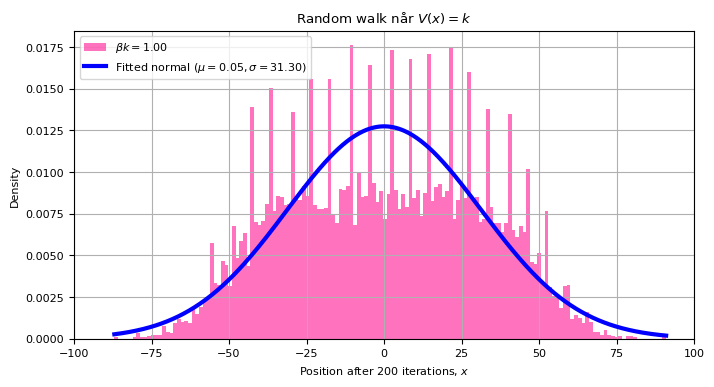

In [75]:
run_case(V_const, B, r"$V(x)=k$", pos0_mode="spread", a=True, xlim=(-100, 100))


pos0 min/max: -50 50
final min/max: 37 188 mean: 114.90029702970297


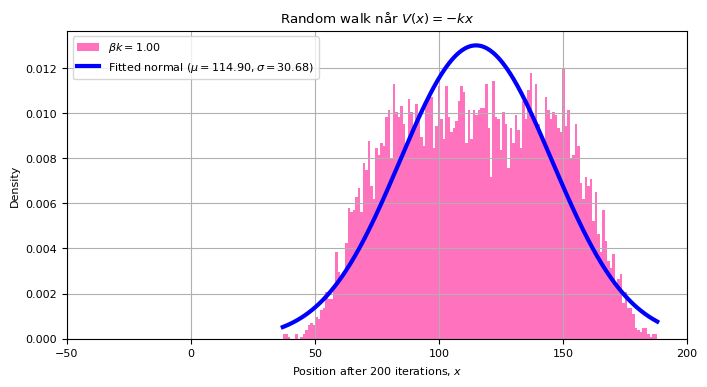

In [66]:
run_case(V_linear, B, r"$V(x)=-kx$", pos0_mode="spread", a=True, xlim=(-50, 200))

#### Diskusjon

For $V(x)=k$ (konstant potensial) ser vi at fordelingen er symmetrisk og tilnærmet normalfordelt rundt $\mu \approx 0$, med $\sigma \approx 31.29$. Dette er i tråd med teorien: når potensialet er konstant, er sannsynlighetene for å gå til høyre og venstre like store ($p^+ = p^- = 1/3$), og prosessen blir en symmetrisk random walk med en ikke-null sannsynlighet for å stå stille. Ifølge sentralgrenseteoremet vil summen av mange uavhengige steg nærme seg en normalfordeling, og variansen vokser lineært med antall tidssteg $T$.

Hvis alle partikler hadde startet i $x=0$, ville vi forventet diffusiv spredning gitt av variansen per steg. For et flatt potensial har vi

$$
p^+ = p^- = p^0 = \frac{1}{3}.
$$

Dette gir

$$
\mathrm{Var}(\Delta x) = \frac{2}{3}.
$$

Med $T=200$ får vi derfor en forventet diffusiv spredning

$$
\sigma_{\text{diff}} = \sqrt{\frac{2T}{3}} 
= \sqrt{\frac{400}{3}} 
\approx 11.5.
$$

I denne simuleringen starter partiklene ikke i $x=0$, men er allerede fordelt over intervallet $[-50,50]$. Den observerte spredningen i sluttfordelingen blir derfor en kombinasjon av startspredning og diffusjon,

$$
\sigma_{\text{total}}^2 \approx \sigma_{\text{start}}^2 + \sigma_{\text{diff}}^2,
$$

som forklarer hvorfor vi får en betydelig større verdi $\sigma \approx 31$ enn $\sigma \approx 11.5$.

For $V(x)=-kx$ ser vi at fordelingen er forskjøvet mot positive $x$-verdier, med $\mu \approx 114.9$. Dette kan forklares ved å beregne forventet drift per steg. Siden
$$
V(x_0+1)-V(x_0)=-k,\qquad V(x_0-1)-V(x_0)=+k,
$$
følger det fra ligning (8) at sannsynligheten for et steg mot høyre er større enn for et steg mot venstre ($p^+ > p^-$). 
$$
p^+ = \frac{1}{1 + e^{-\beta [V(x_0 - 1) - V(x_0 + 1)]} + e^{-\beta [V(x_0) - V(x_0 + 1)]}}
$$

$$
p^- = \frac{1}{1 + e^{-\beta [V(x_0 + 1) - V(x_0 - 1)]} + e^{-\beta [V(x_0) - V(x_0 - 1)]}}
$$
$$
p^0 = \frac{1}{1 + e^{-\beta [V(x_0 + 1) - V(x_0)]} + e^{-\beta [V(x_0 - 1) - V(x_0)]}}
$$


Med $\beta k=1$, gir numerisk verdi $p^+ \approx 0.665$ og $p^- \approx 0.090$, slik at forventet steg blir
$$
\mathbb{E}[\Delta x]=p^+-p^- \approx 0.575.
$$
Etter $T=200$ steg forventer vi derfor
$$
\mathbb{E}[x_T]\approx T\,\mathbb{E}[\Delta x]\approx 200\cdot 0.575 \approx 115,
$$
som stemmer godt med simuleringen. 

Til forskjell fra $V(x)=k$, der $p^+=p^- $ og vi får $\mu \approx 0$ uten drift, gir $V(x)=-kx$ en systematisk drift i tillegg til diffusjon grunnet avtagende potensial. Spredningen $\sigma$ er fortsatt stor fordi starttilstanden er utbredt over $[-50,50]$.


### 2b)

In [ ]:
def simStep_hardcore(Vfunc, B, pos, h, k):
    #Ett tidssteg der alle partikler prøver å flytte én gang i tilfeldig rekkefølge, med hard core exclusion.
    
    Np_local = pos.size
    order = np.random.permutation(Np_local)

    occupied = set(pos.tolist())
    pos=pos.copy()

    for i in order:
        x0 = pos[i]
        p_plus = pPlus(Vfunc, B, x0, k)
        p_min  = pMin( Vfunc, B, x0, k)

        r = np.random.rand()

        if r <= p_min:
            x_new = x0 - h
        elif r > (1 - p_plus):
            x_new = x0 + h
        else:
            continue  

        if x_new in occupied:
            continue

        occupied.remove(x0)
        occupied.add(x_new)
        pos[i] = x_new

    return pos

def simWalk_hardcore(Vfunc, B, pos0, Tp, dt, h, k):
    pos = pos0.copy()
    for _ in range(int(Tp/dt)):
        pos = simStep_hardcore(Vfunc, B, pos, h, k)
    return pos

In [ ]:
def run_case_hardcore(Vfunc, B, V_label, pos0_mode="spread", a=False, xlim=None):
    if pos0_mode == "spread":
        pos0 = np.arange(Np) - Np//2
    else:
        pos0 = np.zeros(Np, dtype=int)

    all_final = []
    for _ in range(runs):
        all_final.append(simWalk_hardcore(Vfunc, B, pos0, Tp, dt, h, k))
    all_final = np.concatenate(all_final)

    print("pos0 min/max:", pos0.min(), pos0.max())
    print("final min/max:", all_final.min(), all_final.max(), "mean:", all_final.mean())


    if a==True: #hvis jeg skal ha normalfordeling på hsitogrammet
        mu = np.mean(all_final) #beregner gjennomsnittet av den 
        sigma = np.std(all_final)

        x = np.linspace(all_final.min(), all_final.max(), 400)
        pdf = (1/(sigma*np.sqrt(2*np.pi))) * np.exp(-0.5*((x-mu)/sigma)**2)





    plt.figure()
    plt.hist(all_final, bins=110, density=True, alpha=0.6,
             color="violet", label=rf'$\beta k={B*k:.2f}$')
    if a==True:
        plt.plot(x, pdf, color="Blue", linewidth=3, label=rf'Fitted normal ($\mu={mu:.2f}, \sigma={sigma:.2f}$)')
    plt.title(rf"Hardcore når {V_label}")
    plt.xlabel(rf"Position after {Tp} iterations, $x$")
    plt.ylabel("Density")
    plt.xlim(xlim)
    plt.legend()
    plt.grid(True)
    plt.show()


#### Case (i)

pos0 min/max: -50 50
final min/max: -85 84 mean: -0.0031683168316831685


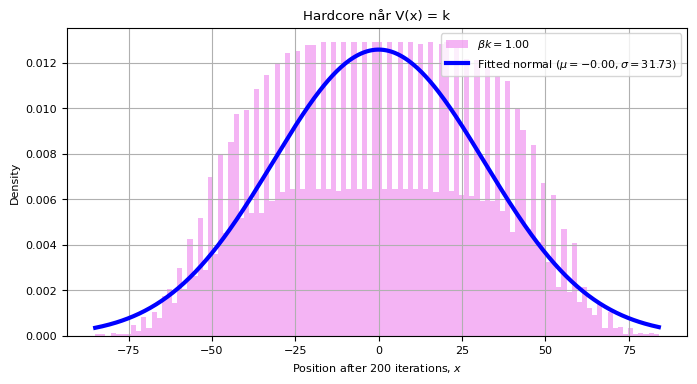

In [79]:
run_case_hardcore(V_const, B, "V(x) = k", pos0_mode="spread", a=True)

#### Case (ii)

pos0 min/max: -50 50
final min/max: -46 195 mean: 41.965643564356434


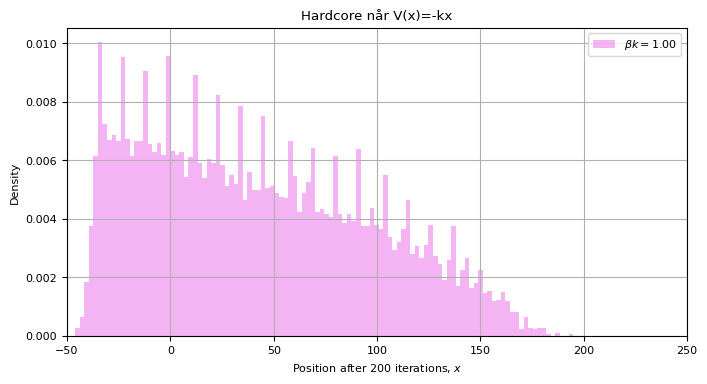

In [31]:
run_case_hardcore(V_linear, B, "V(x)=-kx", pos0_mode="spread", a=False, xlim=(-50, 250))

#### Diskusjon

For $V(x)=k$ (konstant potensial) er energien den samme på alle posisjoner. Fra ligning (8) følger det at $p^+=p^-=p^0=1/3$. Random walken er dermed fortsatt symmetrisk. Forventningsverdien er fortsatt tilnærmet 0 med $\mu \approx -0.02$. Den målte spredningen er $\sigma \approx 31.73 $, tilnærmet det vi så i oppgave 2a (i). Årsaken er at, selv om partiklene ikke kan overlappe, vil de i et flatt potensial i gjennomsnitt forsøke å bevege seg like mye i begge retninger. Hard core-interasksjonen påvirker derfor i liten grad fordeligstypen. Spredningen på rundt 31 forklares på samme måte som i 2a. 

For $V(x)=-kx$, avtar potensialet med økende x, helt likt som i 2a (ii). Overgangssansynligheten med bevegelse mot høyre blir igjen favorisert av samme grunn. Partiklene starter jevnt mellom $[50, 50]$. Sluttresultatet viser at det er en tydlig driv mot høyre, hvorav de havner mellom $-46$ og $195$ og forventningsverdien ligger på $41.97>>0$. En forventningsverdi på $41.97$ er likevel betydlig mindre enn det vi så i 2a (ii), hvor den lå på 115. Fordelingen er også ikke lenger tilnærmet gaussiks, men blir i stedet skjev med høy tetthet mot venstre side og en lang hale mot høyre. Dette kan forklares ved at partiklene starter tett pakket mellom $[-50, 50]$. Partiklene lengst til høyre kan bevege seg relativt fritt i retning av lavere potensial, mens partikler lenger bak ofte hindres av andre partikler foran seg. 

Sammenlignet med oppgave 2a ser vi at hard core-interaksjonen har liten effekt i et flatt potensial som $V(x)=k$, fordi random walken er fortsatt symmetrisk og blokkeringer skjer omtrent like ofte i begge retninger. For det lineære potensialet $V(x)=-kx$ får interaksjonene derimot stor effekt.




### 2c)

pos0 min/max: -50 50
final min/max: -86 80 mean: 0.05841584158415842


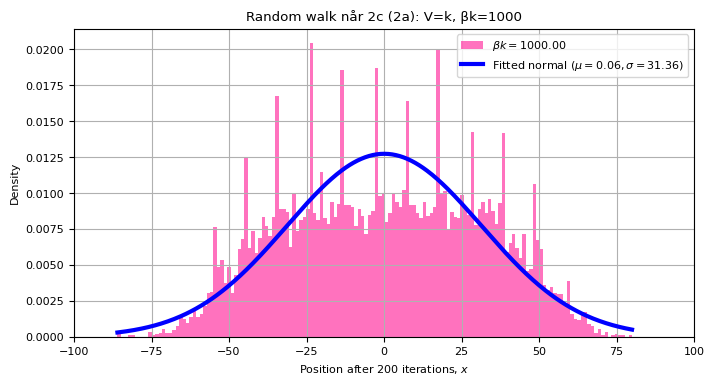

In [68]:
run_case(V_const, 1000, "2c (2a): V=k, βk=1000", pos0_mode="spread", a=True, xlim=(-100, 100))


pos0 min/max: -50 50
final min/max: 150 250 mean: 200.0


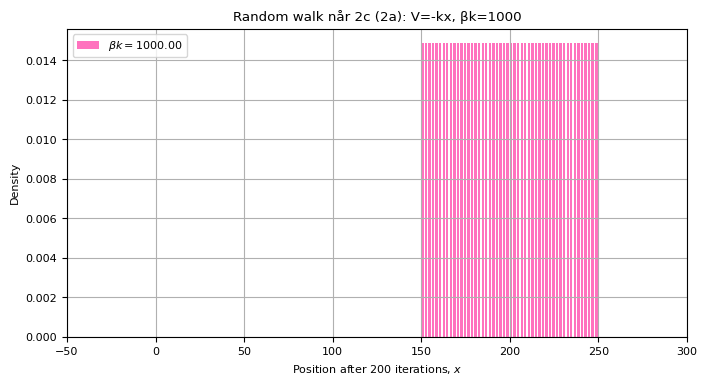

In [81]:
run_case(V_linear, 1000, "2c (2a): V=-kx, βk=1000", pos0_mode="spread", xlim=(-50, 300))


pos0 min/max: -50 50
final min/max: -85 81 mean: 0.02297029702970297


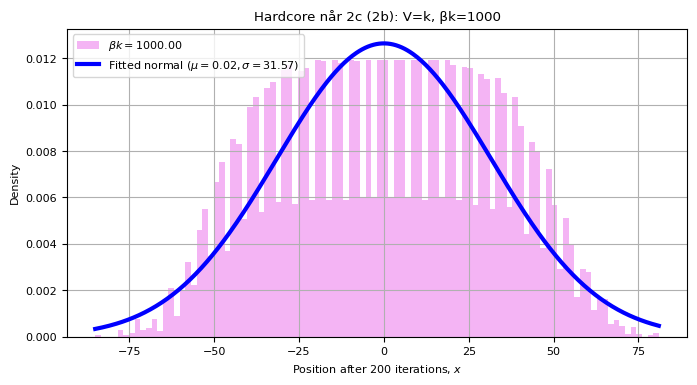

In [11]:

run_case_hardcore(V_const, 1000, "2c (2b): V=k, βk=1000", pos0_mode="spread", a=True)


pos0 min/max: -50 50
final min/max: 50 250 mean: 150.0239603960396


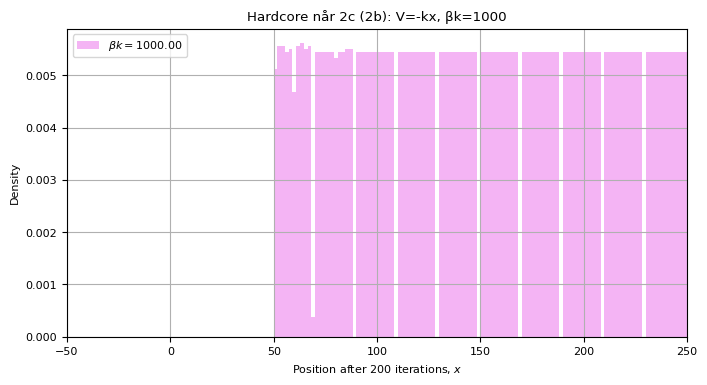

In [34]:
run_case_hardcore(V_linear, 1000, "2c (2b): V=-kx, βk=1000", pos0_mode="spread", a=False, xlim=(-50, 250))

### Diskusjon 

Forskjellen fra 2a, 2b og til de respektive plottene i 2c, er temperaturen. $\beta k=1000$ når $k=1$, betyr $\beta =1000$, som igjen gir $\beta =1/(k_B T) $. Det betyr veldig lav temperatur.

For både 2a (i) og 2b (ii), vil man ikke se noen endirng. Potensialet er konstant, vi får fortsatt like store overgangssanysynlighetene $p^+=p^-=p^0=1/3 $. Det er helt uanvhengig temperaturen. Det kommer fra utrykket av overgangssansynlighetene i likning 8.


Siden alle potensialene er konstante, følger

$$
V(x_0-1)-V(x_0+1)=0, \qquad V(x_0)-V(x_0+1)=0.
$$

Dermed får vi

$$
p^+ =
p^- =
p^0 =
\frac{1}{1 + e^{0} + e^{0}}
=
\frac{1}{3}.
$$


Random walken er fortsatt symmetrisk. Det er ingen drift, og samme diffusjon. 

&emsp; 

For $V(x)=-kx$ ser vi en markant forskjell når temperaturen senkes til $\beta k = 1000$, sammenlignet med tilfellet $\beta k = 1$ gitt i 2a (ii). 

Ved $\beta k=1$ får man både drift og diffusjon. Fordelingen i 2a (ii) er forskjøvet mot høyre og har betydelig bredde med $\mu \approx 114.9$ og $\sigma \approx 30.7$. Når $\beta k = 1000$ blir partiklene veldig forskjøvet uten særlig bredde, fordi overgangssansynlighetene peker kun én vei. Fra ligning 8 får man:
$$
V(x_0-1)-V(x_0+1)=2k,\qquad V(x_0)-V(x_0+1)=k,
$$
slik at
$$
p^+ = \frac{1}{1+e^{-2\beta k}+e^{-\beta k}} \approx 1,
$$
mens
$$
p^- = \frac{1}{1+e^{2\beta k}+e^{\beta k}} \approx 0,
\qquad
p^0 = \frac{1}{1+e^{\beta k}+e^{-\beta k}} \approx 0.
$$
Dermed beveger nesten alle partikler seg mot høyre ved nesten hvert tidssteg.

Dette stemmer med plottet.  Sluttposisjonene ligger i intervallet $[150,250]$ med gjennomsnitt $\mu \approx 200$. Dette samsvarer med at startintervallet er $[-50,50]$ og at hver partikkel flyttes omtrent $+200$ etter $T=200$ steg, altså
$$
x_T \approx x_0 + 200,
$$
som gir sluttintervall $[-50+200,\, 50+200]=[150,250]$ og middelverdi $\mu \approx 200$. Ved så lav temperatur dominerer driften fullstendig og diffusjonen blir sterkt undertrykt.


&emsp; 

Man ser på samme måte en tydlig forskjell for $V(x)=-kx$ med hard core-repusion fra 2b (ii), når temperaturen senkes fra $\beta k = 1$ til $\beta k = 1000$. 

Når $\beta k = 1$, får man fortsatt en tydelig drift mot høyre. Histogrammet er forskjøvet mot positive $x$-verdier, og gjennomsnittet blir $\mu \approx 41.97$. Samtidig er fordelingen relativt bred fordi partiklene kan bevege seg både mot høyre og venstre, selv om steg mot høyre er mer sannsynlige, hvorav $p^+ \approx 0.665$ og $p^- \approx 0.09 $.

Når temperaturen derimot senkes til $\beta k = 1000$, blir overgangssansynlighetene $p^-$ neglisjerbar. 
For det lineære potensialet
$$
V(x)=-kx
$$
får man energiforskjellene
$$
V(x_0+1)-V(x_0)=-k, \qquad V(x_0-1)-V(x_0)=+k.
$$
Setter man dette inn i ligning (8), får man
$$
p^+ = \frac{1}{1+e^{-\beta[V(x_0-1)-V(x_0+1)]}+e^{-\beta[V(x_0)-V(x_0+1)]}}
$$

$$
= \frac{1}{1+e^{-\beta(2k)}+e^{-\beta(k)}}.
$$

Når $\beta k =1000$ blir

$$
e^{-\beta k}=e^{-1000} \approx 0,
\qquad
e^{-2\beta k}=e^{-2000} \approx 0.
$$

Dermed får man

$$
p^+ \approx \frac{1}{1+0+0}=1.
$$

Tilsvarende får man

$$
p^-=\frac{1}{1+e^{\beta(2k)}+e^{\beta(k)}}.
$$

Når $\beta k=1000$ blir

$$
e^{\beta k}=e^{1000}\gg 1,
$$

slik at

$$
p^- \approx 0.
$$

Dermed får vi

$$
\mathbb{E}[\Delta x]=p^+-p^- \approx 1.
$$

Partiklene flytter seg altså i teorien ett steg mot høyre i hvert tidssteg. Man ville derfor tenkt at det siste plottet skulle ligne plottet fra 2a (ii) med $\beta k = 1000$, ettersom begge har $p^+ \approx 1$. Vi ser derimot at plottet fra 2b (ii) med $\beta k = 1000$, har en "spredning" mellom 50 og 250, i stedet for 150 og 250. Dette skyldes hard core-repusjon hvoav at partikler ikke kan passere hverandre. Når alle partikler forsøker å bevege seg mot høyre, kan noen bli blokkert av partikler foran seg og dermed bli stående stille i enkelte tidssteg. 

$$
x_T = x_0 + N_{\text{acc}},
$$

der $N_{\text{acc}}$ er antall aksepterte steg. På grunn av blokkeringene varierer dette tallet omtrent mellom $100$ og $200$, noe som gir sluttposisjoner i intervallet

$$
x_T \in [50,250],
$$

som samsvarer med det vi ser i plottet. 




Et spørsmål man kan sitte igjen med her er muligens hvorfor man ikke får noen feil når man i definisjonen sier at den totale sannsynligheten er noe over 1. I og med at $p^+=1$, eksakt fra definisjonen, og $p^- $ blir noe i en stærrelsesorden av $\exp(-1000)$, som riktig nok er veldig nært 0, men ikke helt. Man skulle kanskje tenkt at det ville rotet til matematikken, men numeriske metoder er vel ikke presise nok til å plukke opp på det. 









### Oppgave 3